               """PROYECTO NASA"""
"Turbofan Engine Degradation Simulation Data Set"

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Ruta donde se subio la carpeta en el Drive
ruta = "/content/drive/MyDrive/Proyecto NASA/CMAPSSData"

# Listamos los archivos que hay en esa carpeta
print(os.listdir(ruta))

['train_FD001.txt', 'test_FD001.txt', 'train_FD003.txt', 'test_FD003.txt', 'train_FD002.txt', 'test_FD002.txt', 'train_FD004.txt', 'test_FD004.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD004.txt', 'RUL_FD003.txt', 'readme.txt', 'Damage Propagation Modeling.pdf']


In [3]:
import pandas as pd

# Nombres de las 26 columnas (el archivo no los trae)
columnas = ["unit", "cycle", "op_1", "op_2", "op_3"] + [f"sensor_{i}" for i in range(1, 22)]

# Cargamos el train de FD001 (separado por espacios, sin encabezado)
ruta = "/content/drive/MyDrive/Proyecto NASA/CMAPSSData"
train = pd.read_csv(f"{ruta}/train_FD001.txt", sep=r"\s+", header=None, names=columnas)

print("Dimensiones:", train.shape)

Dimensiones: (20631, 26)


In [4]:
# Primeras filas para ver como se ven los datos
train.head()

,unit,cycle,op_1,op_2,op_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
# Ficha tecnica: Tipos de dato y nulos
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   op_1       20631 non-null  float64
 3   op_2       20631 non-null  float64
 4   op_3       20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor

In [6]:
# Cuantos motores distintos hay en FD001
print("Cantidad de motores:", train["unit"].nunique())

Cantidad de motores: 100


In [7]:
# Cuántos ciclos vivió cada motor (su vida útil hasta fallar)
ciclos_por_motor = train.groupby("unit")["cycle"].max()

print(ciclos_por_motor)

unit
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64


In [8]:
# Estadisticas de la vida util de los motores
print(ciclos_por_motor.describe())

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


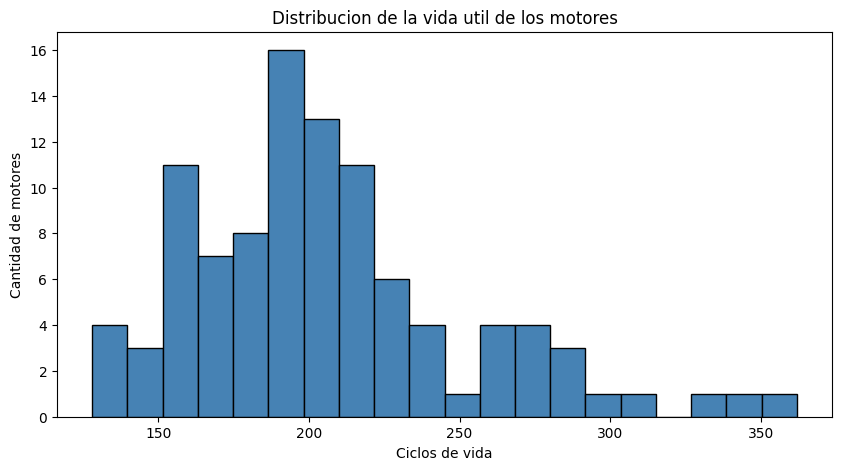

In [9]:
# Histograma de la vida util de los motores
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(ciclos_por_motor, bins=20, color="steelblue", edgecolor="black")
plt.title("Distribucion de la vida util de los motores")
plt.xlabel("Ciclos de vida")
plt.ylabel("Cantidad de motores")
plt.show()

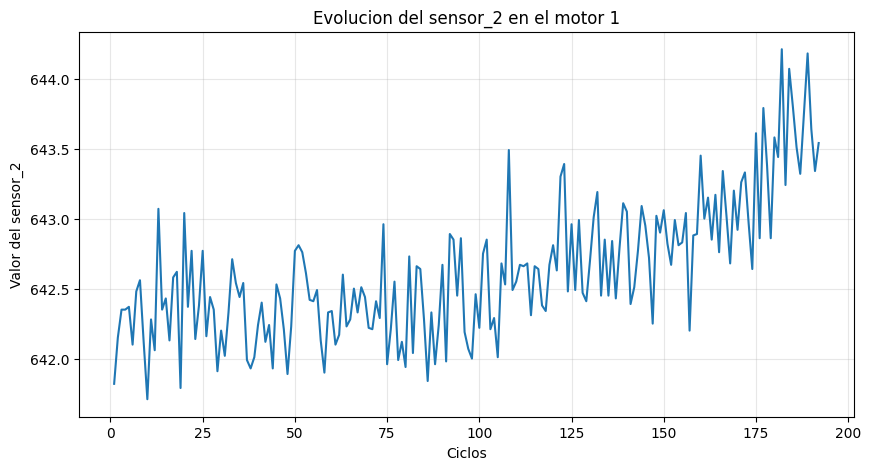

In [10]:
import matplotlib.pyplot as plt

# Nos quedamos solo con las filas del motor 1
motor_1 = train[train["unit"] == 1]

# Graficamos como evoluciona el sensor_2 a los largo de sus ciclos
plt.figure(figsize=(10, 5))
plt.plot(motor_1["cycle"], motor_1["sensor_2"])
plt.title("Evolucion del sensor_2 en el motor 1")
plt.xlabel("Ciclos")
plt.ylabel("Valor del sensor_2")
plt.grid(True, alpha=0.3)
plt.show()

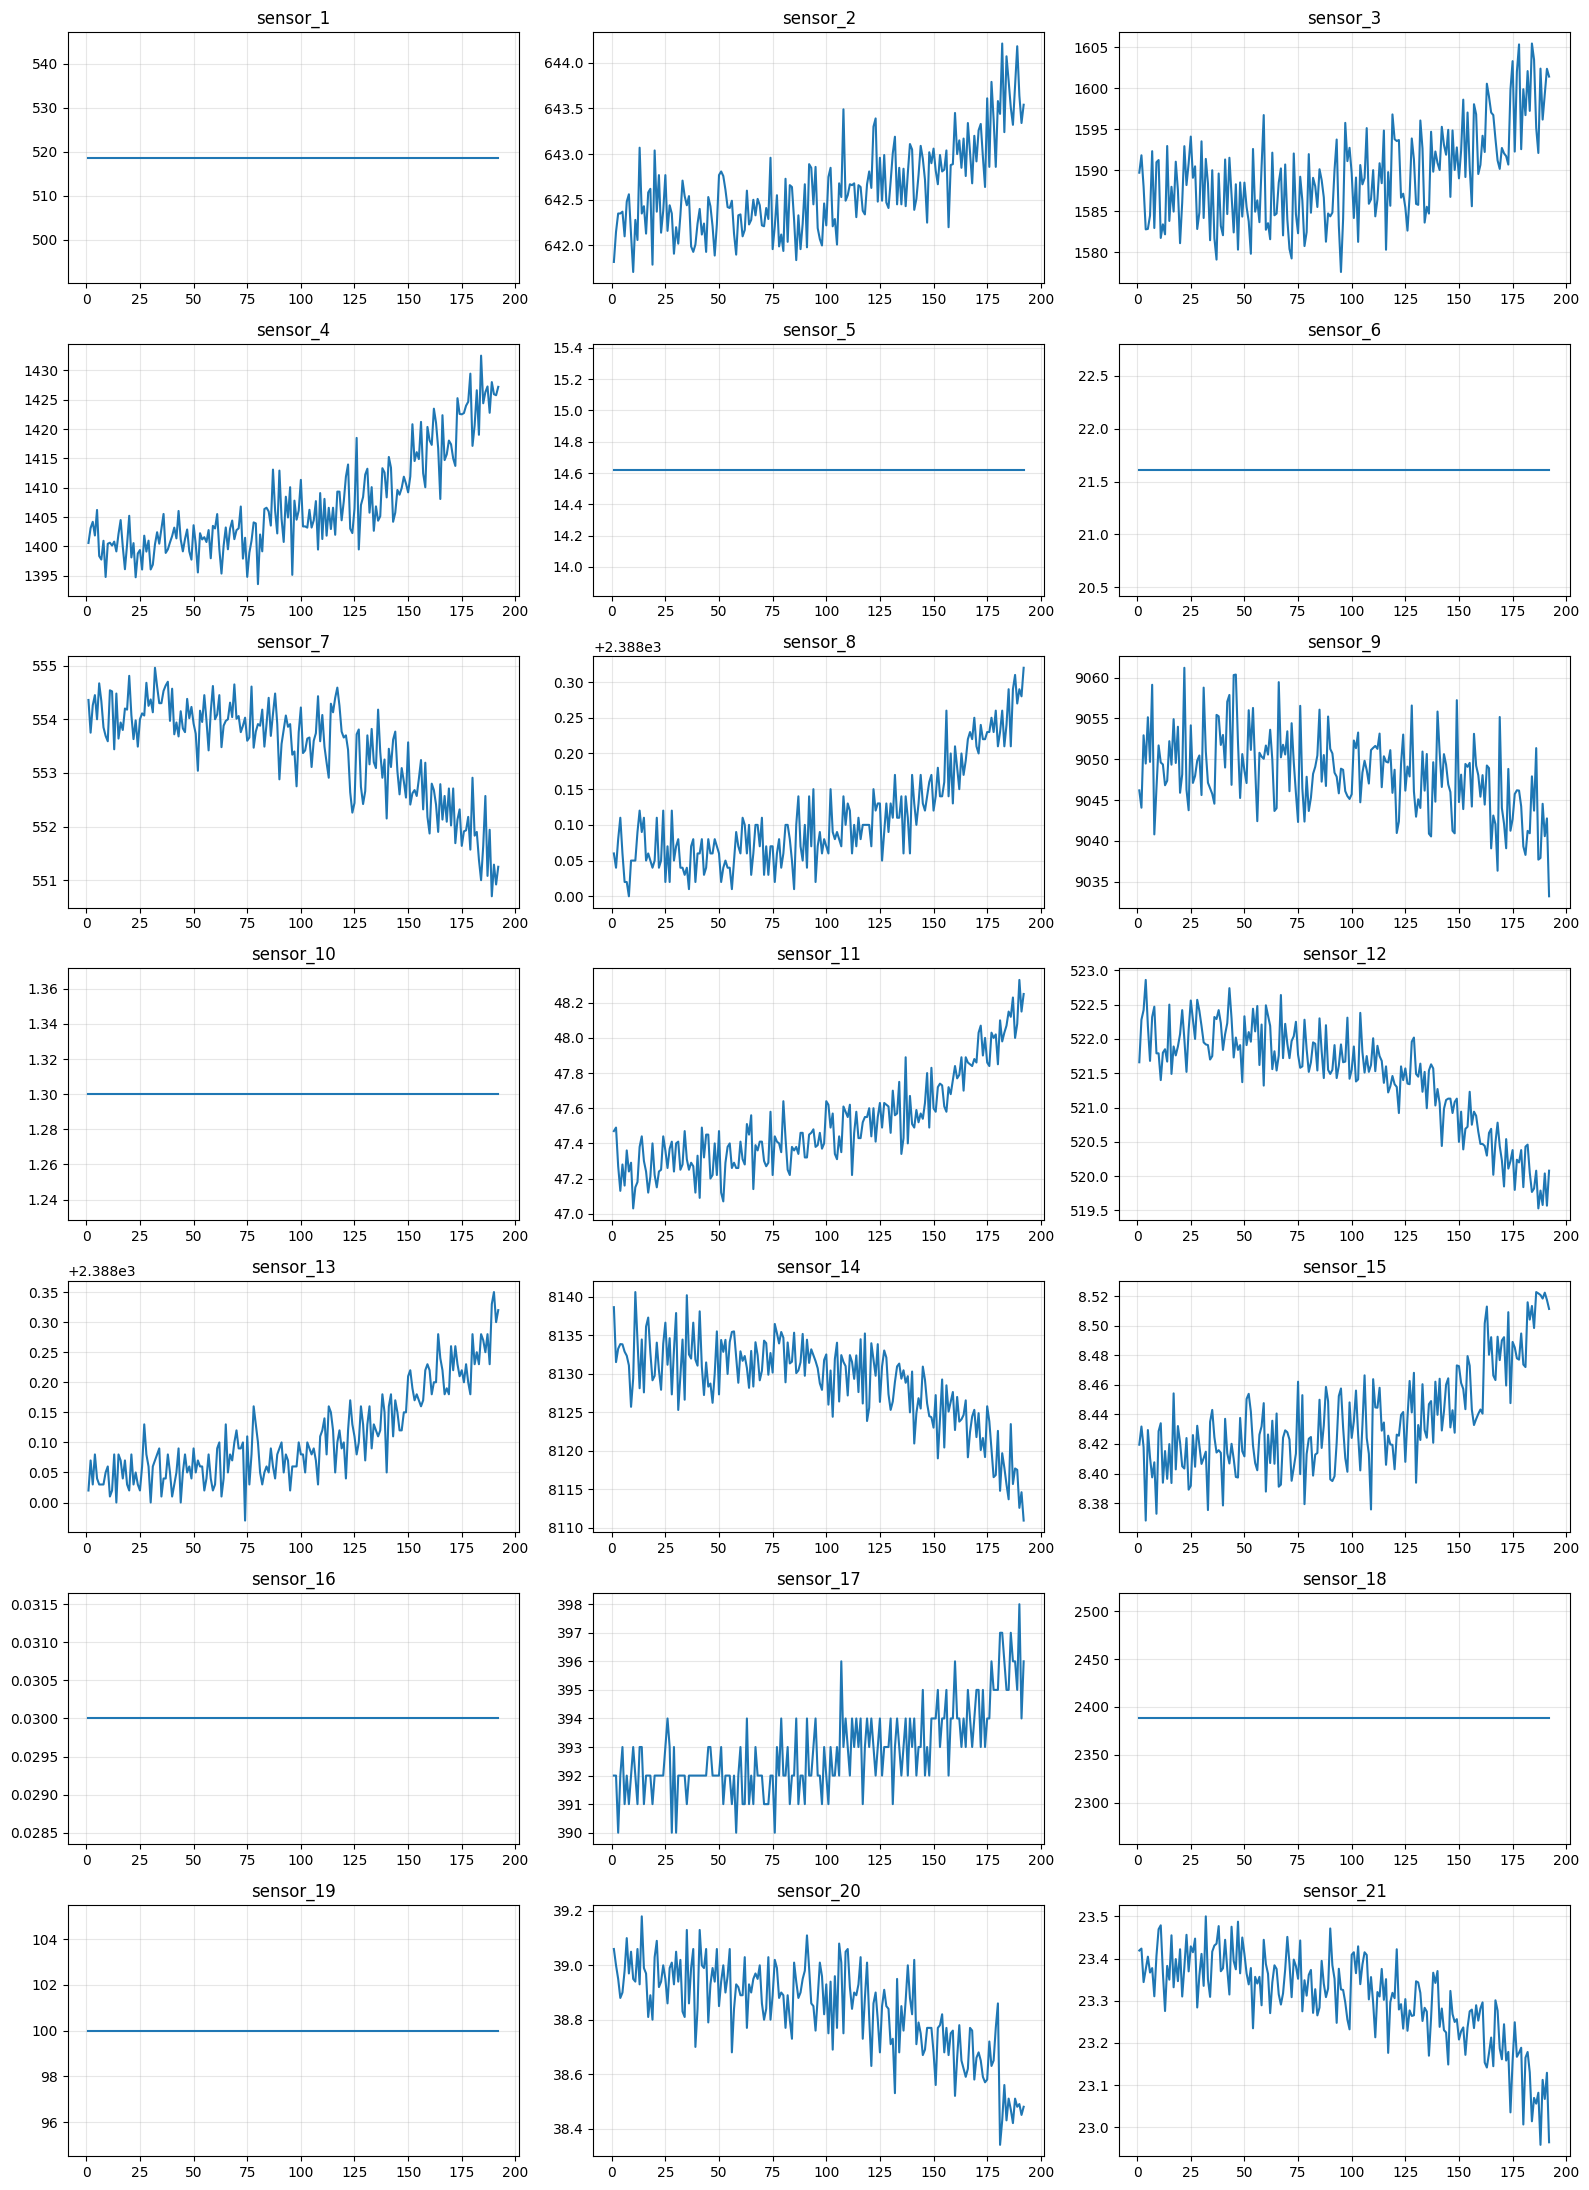

In [11]:
# Nos quedamos con el motor 1
motor_1 = train[train["unit"] == 1]

# Lista de los 21 sensores
sensores = [f"sensor_{i}" for i in range(1, 22)]

# Creamos una grilla de las 7 filas x 3 columnas = 21 espacios (uno por sensor)
fig, axes = plt.subplots(7, 3, figsize=(16, 22))
axes = axes.flatten() # Convertimos la grilla 2D en una lista simple para recorrerla facil

# Recorremos cada sensor y lo dibujamos en su espacio
for i, sensor in enumerate(sensores):
  axes[i].plot(motor_1["cycle"], motor_1[sensor])
  axes[i].set_title(sensor)
  axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# Registro previo (auditoria)
print("Columnas antes:", train.shape[1])

# Sensores planos (sin tendencia) que no aportan informacion
sensores_planos = ["sensor_1","sensor_5","sensor_6","sensor_10","sensor_16",
                   "sensor_18","sensor_19",]

# Los eliminamos (errors='ignore' lo hace idempotente)
train = train.drop(columns=sensores_planos, errors='ignore')

# Registro posterior
print("Columnas despues:", train.shape[1])
print("Columnas restantes:", list(train.columns))

Columnas antes: 26
Columnas despues: 19
Columnas restantes: ['unit', 'cycle', 'op_1', 'op_2', 'op_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [13]:
# Revisamos estadisticas de algunos sensores utiles para detectar valores absurdos
sensores_a_revisar = ["sensor_2","sensor_7","sensor_8","sensor_11","sensor_14",]

train[sensores_a_revisar].describe()

,sensor_2,sensor_7,sensor_8,sensor_11,sensor_14
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,642.680934,553.367711,2388.096652,47.541168,8143.752722
std,0.500053,0.885092,0.070985,0.267087,19.076176
min,641.210000,549.850000,2387.900000,46.850000,8099.940000
25%,642.325000,552.810000,2388.050000,47.350000,8133.245000
50%,642.640000,553.440000,2388.090000,47.510000,8140.540000
75%,643.000000,554.010000,2388.140000,47.700000,8148.310000
max,644.530000,556.060000,2388.560000,48.530000,8293.720000


In [14]:
train[["op_1", "op_2", "op_3"]].describe()

,op_1,op_2,op_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


In [15]:
# Registro previo al DROP (auditoria)
print("Columnas antes:", train.shape[1])

# Variables operativas (practicamente constantes en FD001, no aportan valor)
variables_op = ["op_1", "op_2", "op_3"]

train = train.drop(columns=variables_op, errors="ignore")

# Registro posterior al DROP
print("Columnas despues:", train.shape[1])
print("Columnas restantes:", list(train.columns))

Columnas antes: 19
Columnas despues: 16
Columnas restantes: ['unit', 'cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [16]:
# Paso 1: calculamos el ciclo maximo (ciclo de falla) de cada motor
ciclo_max = train.groupby("unit")["cycle"].transform("max")

# Paso 2: el RUL es ese maximo menos el ciclo actual
train["RUL"] = ciclo_max - train["cycle"]

# Verificamos mirando el motor 1
print(train[train["unit"] == 1][["unit", "cycle", "RUL"]].head())
print(train[train["unit"] == 1][["unit", "cycle", "RUL"]].tail())

   unit  cycle  RUL
0     1      1  191
1     1      2  190
2     1      3  189
3     1      4  188
4     1      5  187
     unit  cycle  RUL
187     1    188    4
188     1    189    3
189     1    190    2
190     1    191    1
191     1    192    0


In [17]:
# Verificamos que el motor 2 tambien tiene su RUL correcto
print(train[train["unit"] == 2][["unit", "cycle", "RUL"]].tail())

     unit  cycle  RUL
474     2    283    4
475     2    284    3
476     2    285    2
477     2    286    1
478     2    287    0


In [18]:
# Lista con las columnas que van como feature (los 14 sensores + el ciclo)
feature = ["cycle", "sensor_2","sensor_3","sensor_4","sensor_7","sensor_8",
           "sensor_9","sensor_11","sensor_12","sensor_13","sensor_14","sensor_15",
           "sensor_17","sensor_20","sensor_21"]

# X = las pistas (features)
X = train[feature]

# y = el objetivo (lo que queremos predecir)
y = train["RUL"]

# Verificamos las dimensiones
print("X (features):", X.shape)
print("y (objetivo):", y.shape)

X (features): (20631, 15)
y (objetivo): (20631,)


In [19]:
# Importamos la libreria y funcion que parte los datos
from sklearn.model_selection import train_test_split

# Partimos X e y en train (80 %) y test (20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Verificamos los tamaños
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

X_train: (16504, 15) | y_train: (16504,)
X_test: (4127, 15) | y_test: (4127,)


In [20]:
# Importamos el modelo de REGRESION LINEAL
from sklearn.linear_model import LinearRegression

# Paso 1: creamos el modelo (vacio, sin entrenar todavia)
modelo = LinearRegression()

# Paso 2: entrenamos el modelo con los datos de entrenamiento
modelo.fit(X_train, y_train)

# Paso 3: predecimos el RUL sobre los datos de test (que el modelo no vio)
predicciones = modelo.predict(X_test)

# Miramos las primeras 5 predicciones VS los valores reales
print("Predicciones:", predicciones[:5].round(1))
print("Reales:", y_test[:5].values)

Predicciones: [ 68.7  32.4 187.6 -53.  104.5]
Reales: [135   2 217   0 178]


In [21]:
# Importamos las metricas de regresion de scikit-learn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculamos las metricas comparando lo real (y_test) VS lo predicho (predicciones)
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print(f"MAE: {mae:.2f} ciclos")
print(f"RMSE: {rmse:.2f} ciclos")
print(f"R2: {r2:.4f}")

MAE: 30.53 ciclos
RMSE: 39.70 ciclos
R2: 0.6550


In [22]:
# Importamos el modelo K-VECINOS (KNN) para regresion
from sklearn.neighbors import KNeighborsRegressor

# Paso 1: creamos el modelo (con K=5 por defecto)
modelo_knn = KNeighborsRegressor()

# Paso 2: entrenamos
modelo_knn.fit(X_train, y_train)

# Paso 3: Predecimos sobre el test
predicciones_knn = modelo_knn.predict(X_test)

# Evaluamos con las mismas 3 metricas
mae_knn = mean_absolute_error(y_test, predicciones_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, predicciones_knn))
r2_knn = r2_score(y_test, predicciones_knn)

print(f"MAE: {mae_knn:.2f} ciclos")
print(f"RMSE: {rmse_knn:.2f} ciclos")
print(f"R2: {r2_knn:.4f}")

MAE: 28.41 ciclos
RMSE: 39.71 ciclos
R2: 0.6548


In [23]:
# Importamos el escalador
from sklearn.preprocessing import StandardScaler

# Creamos el escalador
scaler = StandardScaler()

# Lo "ajustamos" con el train y transformamos el train
X_train_scaled = scaler.fit_transform(X_train)

# Transformamos el test (con la misma escala aprendida del train)
X_test_scaled = scaler.transform(X_test)

print("Datos escalados ✅")
print("Ejemplo - antes:", X_train.iloc[0].values[:3].round(2))
print("Ejemplo - despues:", X_train_scaled[0][:3].round(2))

Datos escalados ✅
Ejemplo - antes: [  24.    642.5  1590.83]
Ejemplo - despues: [-1.24 -0.37  0.05]


In [24]:
# Creamos el modelo K-VECINOS (KNN) "ESCALADO" (k=5 por defecto, igual que antes)
modelo_knn_scaled = KNeighborsRegressor()

# Entrenamos con los datos ESCALADOS
modelo_knn_scaled.fit(X_train_scaled, y_train)

# Predecimos sobre el test ESCALADO
predicciones_knn_scaled = modelo_knn_scaled.predict(X_test_scaled)

# Evaluamos con las mismas 3 metricas
mae = mean_absolute_error(y_test, predicciones_knn_scaled)
rmse = np.sqrt(mean_squared_error(y_test, predicciones_knn_scaled))
r2 = r2_score(y_test, predicciones_knn_scaled)

print(f"MAE: {mae:.2f} ciclos")
print(f"RMSE: {rmse:.2f} ciclos")
print(f"R2: {r2:.4f}")

MAE: 27.76 ciclos
RMSE: 39.28 ciclos
R2: 0.6623


In [25]:
# Probamos distintos valores de K y guardamos el R2 en cada uno
valores_k = [3, 5, 10, 15, 20, 25, 30, 50]

print("Resultados por cada K: \n")
for k in valores_k:
  # Usamos "knn" como nombre para no pisar otras variables
  knn = KNeighborsRegressor(n_neighbors=k)
  knn.fit(X_train_scaled, y_train)
  pred = knn.predict(X_test_scaled)

  # Calculamos las metricas
  mae = mean_absolute_error(y_test, pred)
  rmse = np.sqrt(mean_squared_error(y_test, pred))
  r2 = r2_score(y_test, pred)

  print(f"K={k:>3}) MAE: {mae:.2f} ciclos | RMSE: {rmse:.2f} ciclos | R2: {r2:.4f}")

Resultados por cada K: 

K=  3) MAE: 29.27 ciclos | RMSE: 41.59 ciclos | R2: 0.6215
K=  5) MAE: 27.76 ciclos | RMSE: 39.28 ciclos | R2: 0.6623
K= 10) MAE: 26.75 ciclos | RMSE: 37.62 ciclos | R2: 0.6902
K= 15) MAE: 26.35 ciclos | RMSE: 36.99 ciclos | R2: 0.7005
K= 20) MAE: 26.18 ciclos | RMSE: 36.74 ciclos | R2: 0.7046
K= 25) MAE: 26.11 ciclos | RMSE: 36.61 ciclos | R2: 0.7066
K= 30) MAE: 26.09 ciclos | RMSE: 36.53 ciclos | R2: 0.7078
K= 50) MAE: 26.00 ciclos | RMSE: 36.37 ciclos | R2: 0.7105


In [26]:
# Importamos el arbol de decision para regresion (DECISION TREES)
from sklearn.tree import DecisionTreeRegressor

# Creamos el modelo (con random_state para que sea reproducible)
arbol = DecisionTreeRegressor(random_state=42)

# Entrenamos con los datos SIN escalar (los arboles no necesitan escala)
arbol.fit(X_train, y_train)

# Predecimos sobre el test (tambien sin escalar)
pred_arbol = arbol.predict(X_test)

# Evaluamos
mae = mean_absolute_error(y_test, pred_arbol)
rmse = np.sqrt(mean_squared_error(y_test, pred_arbol))
R2 = r2_score(y_test, pred_arbol)

print(f"MAE: {mae:.2f} ciclos")
print(f"RMSE: {rmse:.2f} ciclos")
print(f"R2: {r2:.4}")

MAE: 35.84 ciclos
RMSE: 52.20 ciclos
R2: 0.7105


In [27]:
            #### VER POSIBLE OVERFITTING ####
# Predicciones sobre el TRAIN (los datos que el arbol ya vio)
pred_train = arbol.predict(X_train)
r2_train = r2_score(y_train, pred_train)

# Predicciones sobre el TEST (datos nuevos)
pred_test = arbol.predict(X_test)
r2_test = r2_score(y_test, pred_test)

print(f"R2 en TRAIN: {r2_train:.4f}")
print(f"R2 en TEST: {r2_test:.4f}")

R2 en TRAIN: 1.0000
R2 en TEST: 0.4035


In [28]:
# Probamos distintas profundidades maximas
profundidades = [2, 3, 5, 7, 10, 15, 20]

print("Resultados por profundidad: \n")
for prof in profundidades:
  # Creamos el arbol con esa profundidad maxima
  arbol = DecisionTreeRegressor(max_depth=prof, random_state=42)
  arbol.fit(X_train, y_train)

  # R2 en train y test, para ver el overfittin
  r2_train = r2_score(y_train, arbol.predict(X_train))
  r2_test = r2_score(y_test, arbol.predict(X_test))

  print(f"max_depth={prof:>2} → R2 train: {r2_train:.4f} | R2 test: {r2_test:.4f}")

Resultados por profundidad: 

max_depth= 2 → R2 train: 0.6144 | R2 test: 0.6095
max_depth= 3 → R2 train: 0.6633 | R2 test: 0.6546
max_depth= 5 → R2 train: 0.7071 | R2 test: 0.6851
max_depth= 7 → R2 train: 0.7350 | R2 test: 0.6879
max_depth=10 → R2 train: 0.8015 | R2 test: 0.6239
max_depth=15 → R2 train: 0.9323 | R2 test: 0.4840
max_depth=20 → R2 train: 0.9913 | R2 test: 0.4175


In [29]:
# Importamos RANDOM FOREST para regresion
from sklearn.ensemble import RandomForestRegressor

# Creamos el modelo (100 arboles por defecto, random_state para reproducibilidad)
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

# Entrenamos con los datos SIN escalar (es un ensamble de arboles)
rf.fit(X_train, y_train)

# R2 en train y test, para chequear overfittin
r2_train = r2_score(y_train, rf.predict(X_train))
r2_test = r2_score(y_test, rf.predict(X_test))

# Metricas completas sobre el test
pred_rf = rf.predict(X_test)
mae = mean_absolute_error(y_test, pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, pred_rf))

print(f"R2 en TRAIN: {r2_train:.4f}")
print(f"R2 en TEST: {r2_test:.4f}")
print(f"MAE: {mae:.2f} ciclos")
print(f"RMSE: {rmse:.2f} ciclos")

R2 en TRAIN: 0.9613
R2 en TEST: 0.7164
MAE: 25.47 ciclos
RMSE: 36.00 ciclos


In [30]:
# Probamos combinaciones de profundidad (el hiperparametro que mas ataca el overfitting)
for prof in [10, 15, 20, None]:
  rf = RandomForestRegressor(max_depth=prof, n_estimators=100,
                             random_state=42, n_jobs=-1)
  rf.fit(X_train, y_train)
  r2_train = r2_score(y_train, rf.predict(X_train))
  r2_test = r2_score(y_test, rf.predict(X_test))
  print(f"max_depth={str(prof):>4} → R2 train: {r2_train:.4f} | R2 test: {r2_test:.4f}")

max_depth=  10 → R2 train: 0.8296 | R2 test: 0.7215
max_depth=  15 → R2 train: 0.9289 | R2 test: 0.7190
max_depth=  20 → R2 train: 0.9568 | R2 test: 0.7174
max_depth=None → R2 train: 0.9613 | R2 test: 0.7164


In [31]:
# Importamos Grid Search
from sklearn.model_selection import GridSearchCV

# 1. Definimos la grilla de hiperparametros a probar
grilla = {
    "max_depth": [10, 15, 20],
    "min_samples_leaf": [1, 5, 10],
    "n_estimators": [100]
}

# 2. Creamos el modelo base (sin hiperparametros fijos, los va a elegir grid search)
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# 3. Creamos el Grid Search
grid = GridSearchCV(
    estimator = rf_base,
    param_grid = grilla,
    cv = 5,
    scoring = "r2",
    n_jobs = -1
)

# 4. Lo entrenamos (esto prueba todas las combinaciones) - puede tardar un poco
grid.fit(X_train, y_train)

# 5. Vemos la mejor combinacion y su resultado
print("Mejores hiperparametros:", grid.best_params_)
print(f"Mejor R2 (en validacion cruzada): {grid.best_score_:.4f}")

Mejores hiperparametros: {'max_depth': 15, 'min_samples_leaf': 10, 'n_estimators': 100}
Mejor R2 (en validacion cruzada): 0.7273


In [32]:
# Grid Search guarda el mejor modelos ya entrenado en .best_estimator_
mejor_rf = grid.best_estimator_

# Lo medimos sobre el TEST (el mismo de todos los modelos anteriores)
r2_train = r2_score(y_train, mejor_rf.predict(X_train))
pred_test = mejor_rf.predict(X_test)
r2_test = r2_score(y_test, pred_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print(f"R2 TRAIN: {r2_train:.4f}")
print(f"R2 TEST: {r2_test:.4f}")
print(f"MAE: {mae:.2f} ciclos")
print(f"RMSE: {rmse:.2f} ciclos")

R2 TRAIN: 0.8396
R2 TEST: 0.7221
MAE: 25.27 ciclos
RMSE: 35.64 ciclos


In [33]:
import pandas as pd

# Funcion que entrena un modelo, lo evalua y devuelve sus metricas
def evaluar_modelo(nombre, modelo, X_tr, X_te):
  modelo.fit(X_tr, y_train)
  pred = modelo.predict(X_te)
  return {
      "Modelo": nombre,
      "R2 test": round(r2_score(y_test, pred), 4),
      "MAE": round(mean_absolute_error(y_test, pred), 2),
      "RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 2),
  }

# Evaluamos los 4 modelos (cada uno con su mejor config y sus datos correctos)
resultados = [
    evaluar_modelo("Regresion Lineal",
                   LinearRegression(), X_train, X_test),
    evaluar_modelo("Arbol de Decision (depth=5)",
                   DecisionTreeRegressor(max_depth=5, random_state=42), X_train, X_test),
    evaluar_modelo("KNN (K=50, escalado)",
                   KNeighborsRegressor(n_neighbors=50), X_train_scaled, X_test_scaled),
    evaluar_modelo("Random Forest (optimizado - Grid Search)",
                   RandomForestRegressor(max_depth=15, min_samples_leaf=10,
                                         n_estimators=100, random_state=42, n_jobs=-1),
                   X_train, X_test),
]

# Armamos la tabla y la ordenamos por R2 (el mejor arriba)
tabla = pd.DataFrame(resultados).sort_values("R2 test", ascending=False).reset_index(drop=True)
print(tabla.to_string(index=False))

                                  Modelo  R2 test   MAE  RMSE
Random Forest (optimizado - Grid Search)   0.7221 25.27 35.64
                    KNN (K=50, escalado)   0.7105 26.00 36.37
             Arbol de Decision (depth=5)   0.6851 27.66 37.93
                        Regresion Lineal   0.6550 30.53 39.70


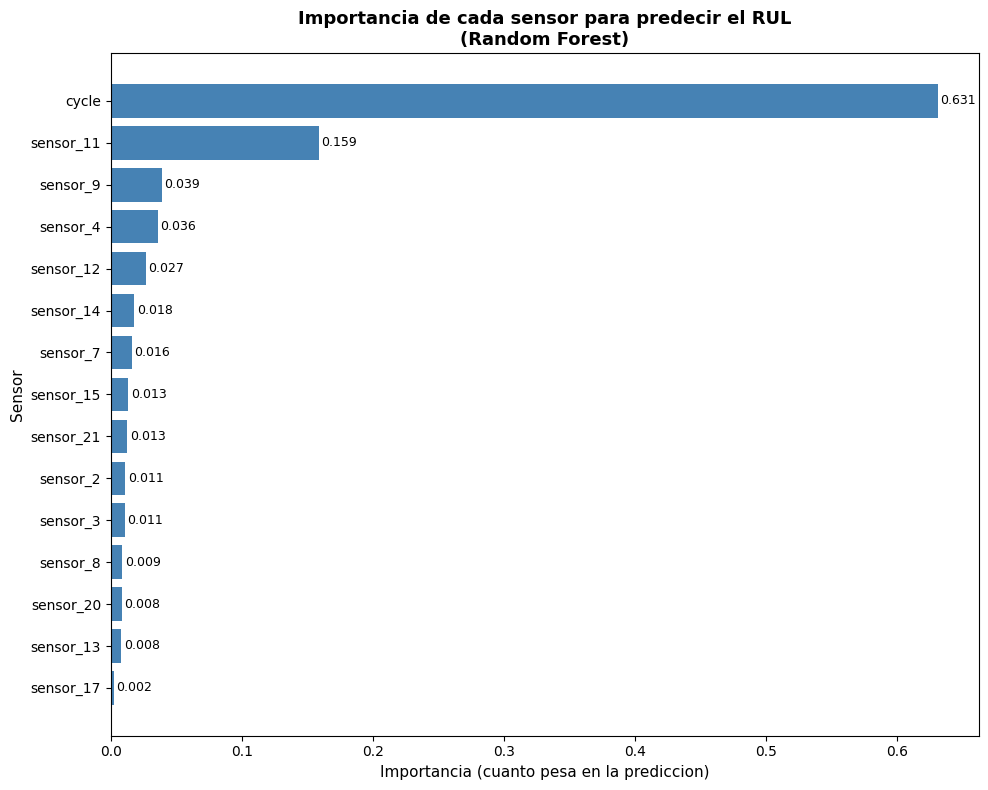

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Sacamos la importancia de cada feature del modelo RF entrenado
importancias = pd.DataFrame({
    "sensor": feature,
    "importancia": mejor_rf.feature_importances_
}).sort_values("importancia", ascending=True) # ascendente: la mas importante queda arriba en barh

# 2. Grafico de barras horizontales
plt.figure(figsize=(10, 8))
barras = plt.barh(importancias["sensor"], importancias["importancia"], color="steelblue")

# 3. Escribimos el valor de importancia al lado de cada barra
for barra, valor in zip(barras, importancias["importancia"]):
  plt.text(valor + 0.002, barra.get_y() + barra.get_height()/2,
           f"{valor:.3f}", va="center", fontsize=9)

# 4. Titulos y etiquetas claras
plt.title("Importancia de cada sensor para predecir el RUL\n(Random Forest)", fontsize=13, fontweight="bold")
plt.xlabel("Importancia (cuanto pesa en la prediccion)", fontsize=11)
plt.ylabel("Sensor", fontsize=11)
plt.tight_layout()
plt.show()

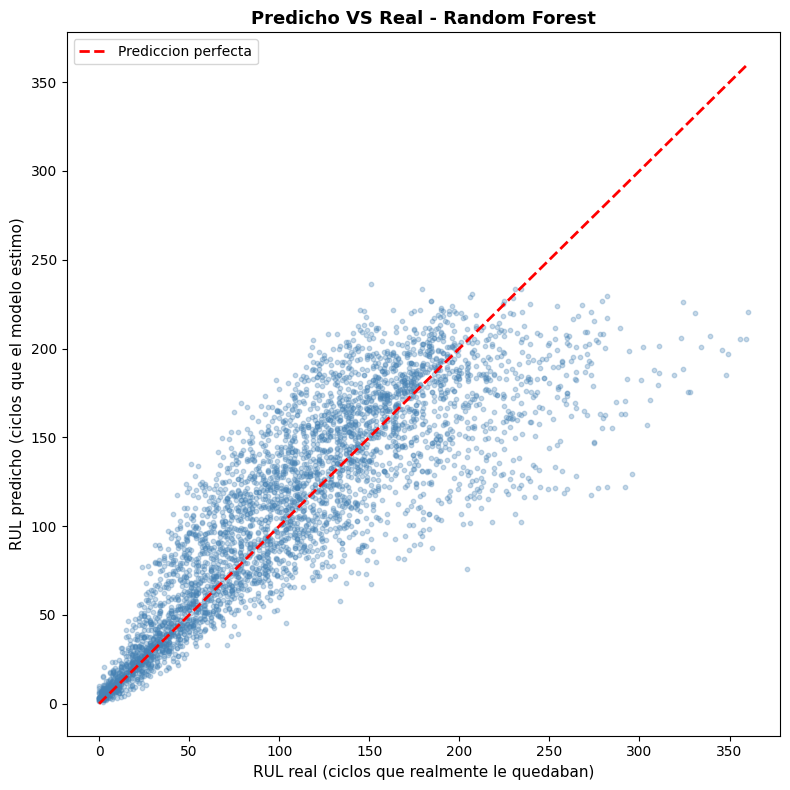

In [35]:
# Predicciones del mejor modelo (RF) sobre el test
pred_test = mejor_rf.predict(X_test)

plt.figure(figsize=(8, 8))

# 1. Los puntos: cada motor (RUL real ~ RUL predicho)
plt.scatter(y_test, pred_test, alpha=0.3, color="steelblue", s=10)

# 2. La linea diagonal de referencia (prediccion perfecta)
limite = max(y_test.max(), pred_test.max())
plt.plot([0, limite], [0, limite], color="red", linestyle="--", linewidth=2,
         label="Prediccion perfecta")

# 3. Titulos y etiquetas
plt.title("Predicho VS Real - Random Forest", fontsize=13, fontweight="bold")
plt.xlabel("RUL real (ciclos que realmente le quedaban)", fontsize=11)
plt.ylabel("RUL predicho (ciclos que el modelo estimo)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
# Tamaño de la ventana (cuantos ciclos seguidos mira la LSTM)
VENTANA = 30

# Features que se usan (las mismas de siempre: cycle + 14 sensores)
# 'feature' ya la tenemos definida de antes

# Tres listas: secuencias(X), respuestas(y), y de que MOTOR es cada ventana
X_seq = []
y_seq = []
motor_seq = []

# Se recorre motor por motor (para no mezclar ciclos de motores distintos)
for motor in train["unit"].unique():
  datos_motor = train[train["unit"] == motor]  # Se queda solo con las filas de ESTE motor
  features_motor = datos_motor[feature].values # Extraemos sus features y su RUL como arrays
  rul_motor = datos_motor["RUL"].values

  # Se disliza la ventana a lo largo de este motor
  for i in range(len(datos_motor) - VENTANA + 1):
    X_seq.append(features_motor[i : i + VENTANA]) # La ventana: 30 ciclos consecutivos de features
    y_seq.append(rul_motor[i + VENTANA - 1])     # La respuesta: el RUL del ULTIMO ciclo de esa ventana
    motor_seq.append(motor)                      # El motor al que pertenece esa ventana

# Se convierten las listas en arrays de numpy (el formato que la LSTM necesita)
X_seq = np.array(X_seq)
y_seq = np.array(y_seq)
motor_seq = np.array(motor_seq)

print("Forma de X_seq:", X_seq.shape)
print("Forma de y_seq:", y_seq.shape)
print("Forma de motor_seq:", motor_seq.shape)

Forma de X_seq: (17731, 30, 15)
Forma de y_seq: (17731,)
Forma de motor_seq: (17731,)


In [37]:
from sklearn.model_selection import  train_test_split

# 1. Dividimos los MOTORES (no las ventanas) en 80/20, al azar
motores = train["unit"].unique()
motores_train, motores_test = train_test_split(motores, test_size=0.2, random_state=42)

# 2. Creamos "mascaras": True/False para cada ventana segun si su motor es de Train o Test
mascara_train = np.isin(motor_seq, motores_train)
mascara_test = np.isin(motor_seq, motores_test)

# 3. Aplicamos las mascaras para separar las ventanas
X_train_seq = X_seq[mascara_train]
y_train_seq = y_seq[mascara_train]
X_test_seq = X_seq[mascara_test]
y_test_seq = y_seq[mascara_test]

print("Train:", X_train_seq.shape, "| Test:", X_test_seq.shape)

Train: (14241, 30, 15) | Test: (3490, 30, 15)


In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Crear la red "vacia" (una pila de capas)
modelos_lstm = Sequential()

# 2. Capa LSTM: 64 neuronas. Lee las secuencias de 30 ciclos x 15 features
modelos_lstm.add(LSTM(64, input_shape=(30, 15)))

# 3. Capa de salida: 1 neurona (predice un numero, el RUL)
modelos_lstm.add(Dense(1))

# 4. Compilamos: definimos como va a predecir
modelos_lstm.compile(optimizer="adam", loss="mse")

# 5. Ver un resumen de la red armada
modelos_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Entrenamos la Red Neuronal (LSTM)
historial = modelos_lstm.fit(
    X_train_seq, y_train_seq,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 11642.2285 - val_loss: 15418.0312
Epoch 2/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 10973.5684 - val_loss: 14673.4277
Epoch 3/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 10347.3057 - val_loss: 13970.3555
Epoch 4/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 9759.4189 - val_loss: 13306.8809
Epoch 5/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 9209.8936 - val_loss: 12681.3096
Epoch 6/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 8696.4082 - val_loss: 12094.0977
Epoch 7/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 8216.7012 - val_loss: 11539.6094
Epoch 8/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 7769.7305 - val_loss: 11021.4785
Epoch 9/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 7353.7964 - val_loss: 10534.1396
Epoch 10/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 6967.1421 - val_loss: 10078.3535
Epoch 11/30
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - 

In [40]:
# Separamos los MOTORES en 80% train / 20% test (al azar, motores enteros)
motores = train["unit"].unique()
motores_train, motores_test = train_test_split(motores, test_size=0.2, random_state=42)

print("Motores train:", len(motores_train))
print("Motores test:", len(motores_test))

Motores train: 80
Motores test: 20


In [41]:
from sklearn.preprocessing import StandardScaler

# 1. Separamos las filas de la tabla segun si el motor es de train o test
datos_train = train[train["unit"].isin(motores_train)]
datos_test = train[train["unit"].isin(motores_test)]

# 2. El scaler APRENDE solo con las features de los motores de train
scaler = StandardScaler()
scaler.fit(datos_train[feature])

# 3. Se crea una copia de la tabla y reemplaza las features por su version escalada
train_escalado = train.copy()
train_escalado[feature] = scaler.transform(train[feature])

print("Escalado aplicado ✅")
print("Ejemplo sensor_9 antes:", train[feature].iloc[0]["sensor_9"].round(2))
print("Ejemplo sensor_9 despues:", train_escalado[feature].iloc[0]["sensor_9"].round(2))

Escalado aplicado ✅
Ejemplo sensor_9 antes: 9046.19
Ejemplo sensor_9 despues: -0.85


In [42]:
VENTANA = 30

X_seq = []
y_seq = []
motor_seq = []

# Recorremos motor por motor, pero ahora sobre la tabla ESCALADA
for motor in train_escalado["unit"].unique():
  datos_motor = train_escalado[train_escalado["unit"] == motor]
  features_motor = datos_motor[feature].values
  rul_motor = datos_motor["RUL"].values

  for i in range(len(datos_motor) - VENTANA + 1):
    X_seq.append(features_motor[i : i + VENTANA])
    y_seq.append(rul_motor[i + VENTANA - 1])
    motor_seq.append(motor)

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)
motor_seq = np.array(motor_seq)

print("Forma de X_seq:", X_seq.shape)
print("Forma de y_seq:", y_seq.shape)
print("Forma de motor_seq:", motor_seq.shape)

Forma de X_seq: (17731, 30, 15)
Forma de y_seq: (17731,)
Forma de motor_seq: (17731,)


In [44]:
# Se separan las ventanas segun si su motor es de train o de test
mascara_train = np.isin(motor_seq, motores_train)
mascara_test = np.isin(motor_seq, motores_test)

X_train_seq = X_seq[mascara_train]
y_train_seq = y_seq[mascara_train]
X_test_seq = X_seq[mascara_test]
y_test_seq = y_seq[mascara_test]

print("Train:", X_train_seq.shape, "| Test:", X_test_seq.shape)

Train: (14241, 30, 15) | Test: (3490, 30, 15)


In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# 1. Se arma la red
modelos_lstm = Sequential()
modelos_lstm.add(Input(shape=(30, 15))) # Capa de entrada (forma de cada secuencia)
modelos_lstm.add(LSTM(64))             # Capa LSTM con 64 neuronas
modelos_lstm.add(Dense(1))              # Capa de salida: 1 numero (el RUL)

modelos_lstm.compile(optimizer="adam", loss="mse")

# 2. Se configura el early stopping (el "vigilante")
early_stop = EarlyStopping(
    monitor="val_loss",         # Que vigila: el error de validacion
    patience=8,                 # Cuantas epochs espera sin mejora antes de frenar
    restore_best_weights=True   # Se queda con la MEJOR version, no la ultima
)

# 3. Entrenamos (hasta 100 epochs, pero frenara solo cuando deje de mejorar)
historial = modelos_lstm.fit(
    X_train_seq, y_train_seq,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)



Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 9906.2783 - val_loss: 12324.2275
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 7838.5620 - val_loss: 10479.0205
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 6478.6431 - val_loss: 9027.0674
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 5408.1958 - val_loss: 7825.1245
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 4542.4434 - val_loss: 6836.7876
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 3838.9910 - val_loss: 6013.5674
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 3241.3445 - val_loss: 5262.6035
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 2749.9866 - val_loss: 4659.4224
Epoch 9/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 2365.6501 - val_loss: 4198.2827
Epoch 10/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 2053.4438 - val_loss: 3805.6006
Epoch 11/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - 

In [47]:
# Se predice sobre el test (los 20 motores que el modelo nunca vio)
pred_lstm = modelos_lstm.predict(X_test_seq)

# Calcula las metricas (las mismas de siempre)
R2 = r2_score(y_test_seq, pred_lstm)
mae = mean_absolute_error(y_test_seq, pred_lstm)
rmse = np.sqrt(mean_squared_error(y_test_seq, pred_lstm))

print(f"R2:    {R2:.4f}")
print(f"MAE:   {mae:.2f} ciclos")
print(f"RMSE:  {rmse:.2f} ciclos")

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
R2:    0.7701
MAE:   19.33 ciclos
RMSE:  27.93 ciclos


110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


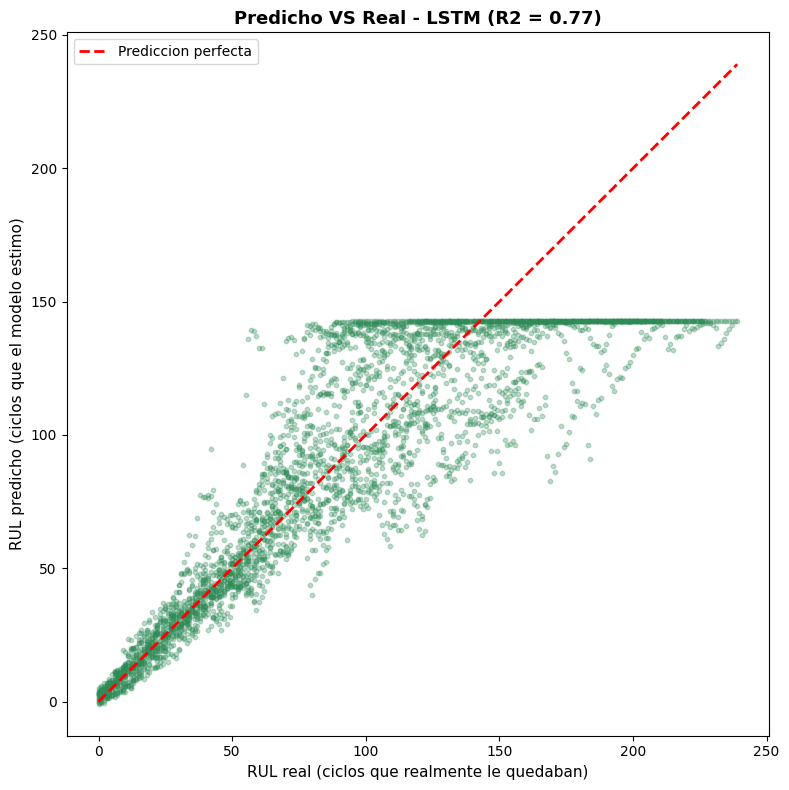

In [49]:
# Predice sobre el test con la LSTM
pred_test = modelos_lstm.predict(X_test_seq)

plt.figure(figsize=(8, 8))

# Dibuja cada secuencia de test como un punto (RUL real VS RUL predicho)
plt.scatter(y_test_seq, pred_test, alpha=0.3, color="seagreen", s=10)

# Traza la diagonal de referencia (prediccion perfecta)
limite = max(y_test_seq.max(), pred_test.max())
plt.plot([0, limite], [0, limite], color="red", linestyle="--", linewidth=2,
         label="Prediccion perfecta")

# Titulos y etiquetas
plt.title("Predicho VS Real - LSTM (R2 = 0.77)", fontsize=13, fontweight="bold")
plt.xlabel("RUL real (ciclos que realmente le quedaban)", fontsize=11)
plt.ylabel("RUL predicho (ciclos que el modelo estimo)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

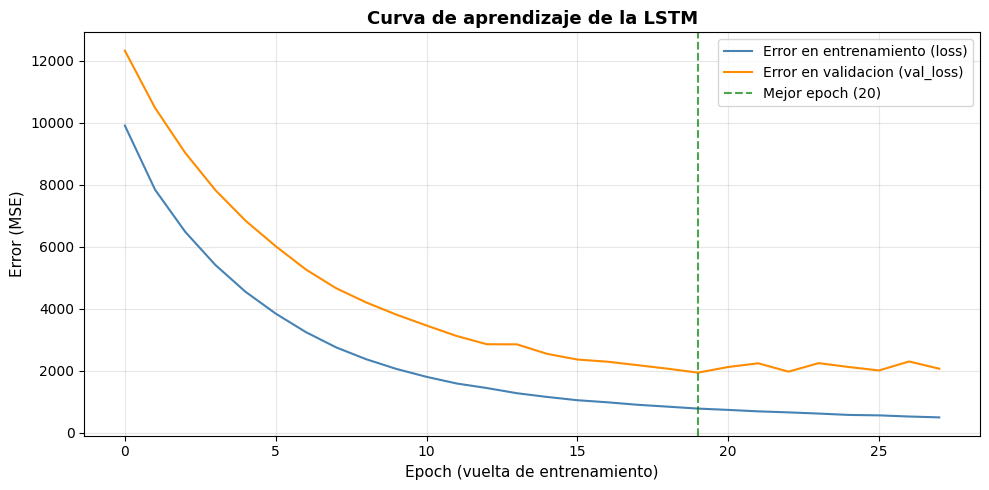

In [50]:
# Extrae el error de entrenamiento y de validacion guardado en el historial
loss = historial.history["loss"]
val_loss = historial.history["val_loss"]

plt.figure(figsize=(10, 5))

# Dibuja ambas curvas a lo largo de los epochs
plt.plot(loss, label="Error en entrenamiento (loss)", color="steelblue")
plt.plot(val_loss, label="Error en validacion (val_loss)", color="darkorange")

# Marca la mejor epoch (la de menor val_loss)
mejor_epoch = val_loss.index(min(val_loss))
plt.axvline(mejor_epoch, color="green", linestyle="--", alpha=0.7,
            label=f"Mejor epoch ({mejor_epoch + 1})")

# Titulos y etiquetas
plt.title("Curva de aprendizaje de la LSTM", fontsize=13, fontweight="bold")
plt.xlabel("Epoch (vuelta de entrenamiento)", fontsize=11)
plt.ylabel("Error (MSE)", fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()